# Estrutura de bandas eletrônica - T-grafeno 

### Aniel de Souza Ribeiro Neto

O seguinte notebook apresenta a modelagem e resolução do T-grafeno, uma molécula derivada do grafeno compoosta por anéis tetragonais de carbono em rede. O objetivo é estudar como efeitos de quadrimerização, variação no tamanho dos anéis, influenncia na estrutura de bandas do material. 

In [1]:
from pythtb import *
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})

## $\bullet$ Visualizando a Célula Unitária

Tomaremos como referência a estrutura de célula unitária apresentada em (Yan et al., 2023).
![image.png](T-Grafeno_Ref.png)



## $\bullet$ Modelando a célula unitária 

Faremos inicialmente a modelagem da célula unitária do T-grafeno através do módulo pythtb seguindo as caracterísitcas descritas por (Yan et al., 2023).

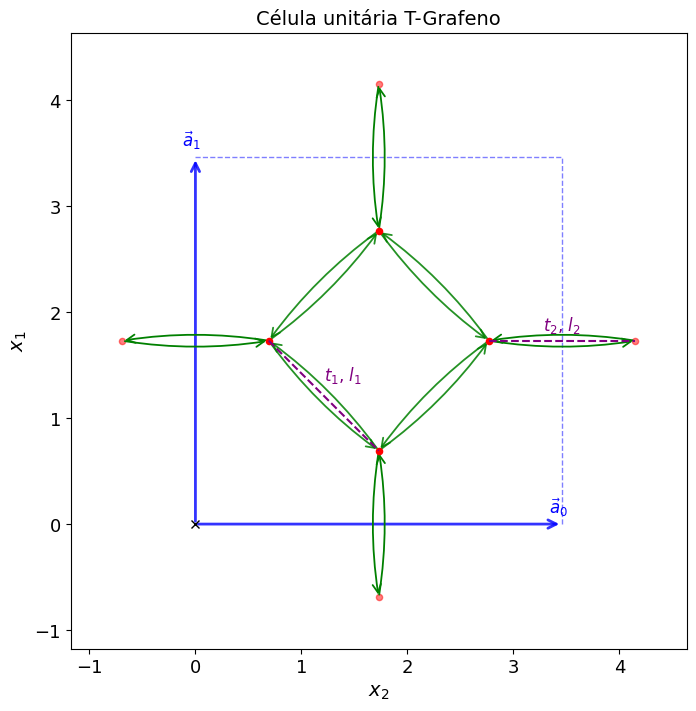

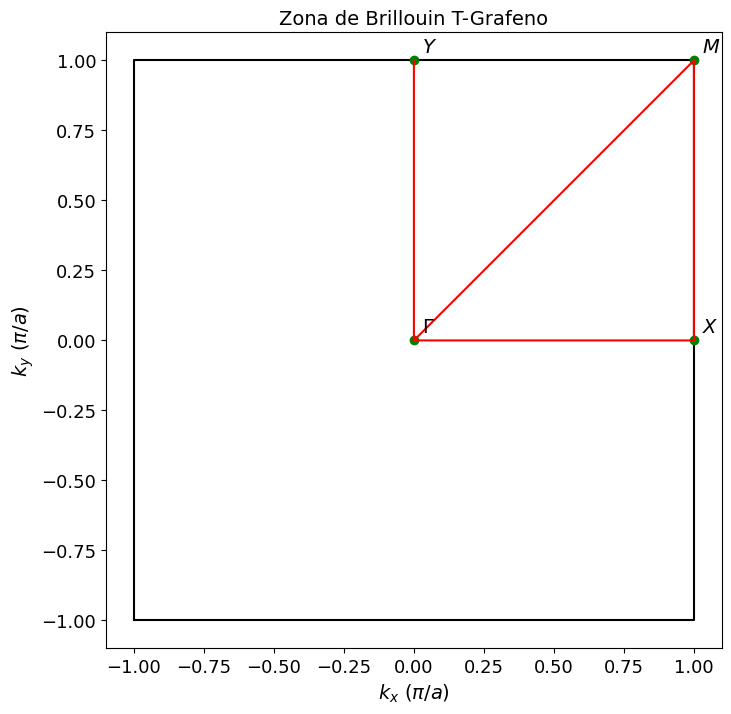

In [2]:
# --- Definindo a geometria do sistema --- 

l1 = 1.468 # (Å) Tamanho das ligações dentro do anel 
l2 = 1.383 # (Å) Tamanho da ligação entre cada anel
a = np.sqrt(2)*l1 + l2 # (Å) Diagonal do anél (quadrado) + ligação entre anéis 

# Vetorese de rede
lat = np.array([
    [a, 0.0],   # a_1
    [0, a]      # a_2
])

# Coordenadas fracionárias dos orbitais 
orb = [
    [0.5 - l1/(np.sqrt(2)*a), 0.5], # 0: esquerda
    [0.5, 0.5 - l1/(np.sqrt(2)*a)], # 1: baixo
    [0.5 + l1/(np.sqrt(2)*a), 0.5], # 2: direita
    [0.5, 0.5 + l1/(np.sqrt(2)*a)]  # 3: cima
]   

# --- Construindo o modelo --- 

# Instanciando 
my_model = tb_model(2, 2, lat, orb)
# Definindo as energias on-site
my_model.set_onsite([0, 0, 0, 0])

t1 = -2.525 # (eV) Hopping dentro do anel
t2 = -2.835 # (eV) Hopping entre anéis

my_model.set_hop(t1, 0, 1, [0, 0]) # esquerda-baixo
my_model.set_hop(t1, 1, 2, [0, 0]) # baixo-direita
my_model.set_hop(t1, 2, 3, [0, 0]) # direita-cima
my_model.set_hop(t1, 3, 0, [0, 0]) # cima-esquerda
my_model.set_hop(t2, 2, 0, [1, 0]) # entre anéis horizontal 
my_model.set_hop(t2, 3, 1, [0, 1]) # entre anéis vertical 


# --- Visualizando ---

# Célula no espaço real
fig, ax = my_model.visualize([0, 1])

coords_cartesianas = np.dot(orb, lat)


p1 = coords_cartesianas[0]  # Orbital 0 (esquerda)
p2 = coords_cartesianas[1]  # Orbital 1 (direita)

p3 = coords_cartesianas[2]
celula_vizinha = [1, 0] 
p4 = coords_cartesianas[0] + celula_vizinha[0]*lat[0] + celula_vizinha[1]*lat[1]

ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color='purple', linestyle='--', linewidth=1.5)
ax.plot([p3[0], p4[0]], [p3[1], p4[1]], color='purple', linestyle='--', linewidth=1.5)

mid_x1 = (p1[0] + p2[0]) / 2
mid_y1 = (p1[1] + p2[1]) / 2
ax.text(mid_x1, mid_y1+0.2, r"$t_1$, $l_1$", color='purple', fontsize=12, va='center')

mid_x2 = (p3[0] + p4[0]) / 2
mid_y2 = (p3[1] + p4[1]) / 2
ax.text(mid_x2, mid_y2 + 0.1, r"$t_2$, $l_2$", color='purple', fontsize=12, ha='center')

fig.set_size_inches(8, 8)
ax.set_title("Célula unitária T-Grafeno")
ax.set_ylabel("$x_1$")
ax.set_xlabel("$x_2$")
fig.savefig("Celula-TGrafeno.pdf")
plt.show()

# Zona de Brillouin
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], 'k')
pts = {r'$\Gamma$': (0, 0), r'$X$': (1, 0), r'$M$': (1, 1), r'$Y$': (0, 1)}
for nome, (kx, ky) in pts.items():
    ax.plot(kx, ky, 'go')
    ax.annotate(nome, (kx, ky), textcoords="offset points", xytext=(6, 6))
caminho = [(0, 0), (1, 1), (1, 0), (0, 0), (0, 1)] # caminho Γ -> M -> X -> Γ -> Y utilizado no artigo
ax.plot(*zip(*caminho), 'r-')
ax.set_aspect('equal')
ax.set_title("Zona de Brillouin T-Grafeno")
ax.set_xlabel(r'$k_x$ ($\pi/a$)'); ax.set_ylabel(r'$k_y$ ($\pi/a$)')
fig.savefig("BZ-TGrafeno.pdf")
plt.show()



## $\bullet$ Resolvendo para diferentes estados de quadrimerização

Partiremos agora para resolução do sistema para encontrarmos a estrutura de bandas do T-grafeno em diferentes estados de quadrimerização. Faremos isso tomando como base: 

$$
 t_1=t_0sen(\varphi), \, \, t_2=t_0cos(\varphi)
$$

com $t_0=-1$, nos permitindo analisar diferentes razões representando os efeitos de quadrimerização. 

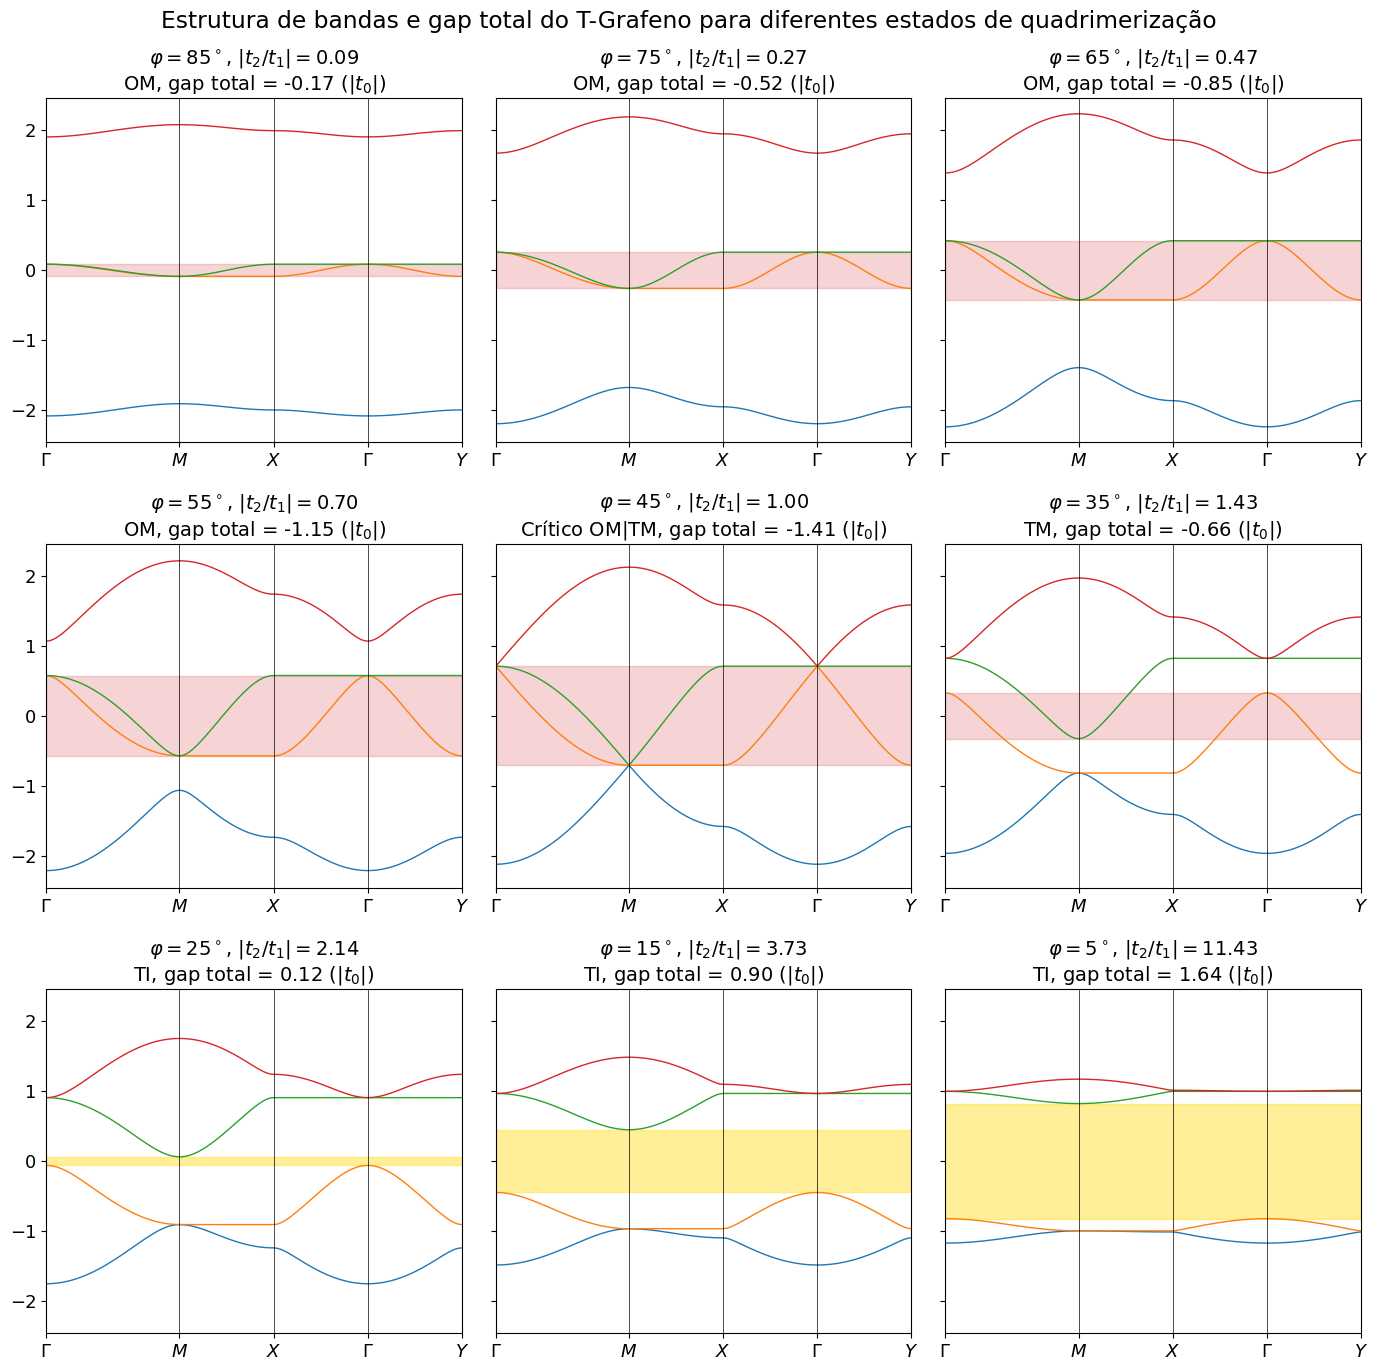

In [3]:
# --- Função para construir o modelo ---

def create_model(phi, t0=-1.0):
    t1 = t0*np.sin(phi)
    t2 = t0*np.cos(phi)
    m = tb_model(2, 2, lat, orb)
    m.set_onsite([0, 0, 0, 0])
    for i, j in [(0, 1), (1, 2), (2, 3), (3, 0)]:
        m.set_hop(t1, i, j, [0, 0])
    m.set_hop(t2, 2, 0, [1, 0])
    m.set_hop(t2, 3, 1, [0, 1])
    return m

# --- Função para determinar fase --- 

N = 60
kmesh = np.array([[i/N, j/N] for i in range(N) for j in range(N)])   # inclui Γ e X

def fase(pdeg, tol=1e-6):
    r = 1/np.tan(np.radians(pdeg))
    if abs(r - 1) < tol:
        return "Crítico OM|TM"
    if abs(r - 2) < tol:
        return "Crítico TM|TI"
    return "OM" if r < 1 else ("TM" if r < 2 else "TI")

# --- Calculando as bandas e o gap total ---

phis_deg = [85,75,65,55,45,35,25,15,5]
path  = [[0, 0], [0.5, 0.5], [0.5, 0], [0, 0], [0, 0.5]]
label = (r'$\Gamma$', r'$M$', r'$X$', r'$\Gamma$', r'$Y$')

fig, axs = plt.subplots(3, 3, figsize=(14, 14), sharey=True)

for ax, pdeg in zip(axs.flat, phis_deg):
    model = create_model(np.radians(pdeg))

    k_vec, k_dist, k_node = model.k_path(path, 121) 
    ev = model.solve_ham(k_pts=k_vec)
    for b in range(4):
        ax.plot(k_dist, ev[:, b], lw=1)

    ev_bz = model.solve_ham(k_pts=kmesh) # gap total na zona de Brillouin inteira
    e2_max = np.max(ev_bz[:, 1])         # topo da banda II
    e3_min = np.min(ev_bz[:, 2])         # fundo da banda III
    gap = e3_min - e2_max                # Gap entre II e III

    if gap > 0: # isolante: janela de energia livre entre as bandas
        ax.axhspan(e2_max, e3_min, color='gold', alpha=0.4)
    else: # metal: região de energia em que II e III se sobrepõem
        ax.axhspan(e3_min, e2_max, color='tab:red', alpha=0.2)

    ax.set_xticks(k_node); ax.set_xticklabels(label)
    for n in k_node: ax.axvline(n, lw=0.5, color='k')
    ax.set_xlim(k_node[0], k_node[-1])
    ax.set_title(rf"$\varphi={pdeg}^\circ$, $|t_2/t_1|={1/np.tan(np.radians(pdeg)):.2f}$"
                 f"\n{fase(pdeg)}, gap total = {gap:.2f} ($|t_0|$)")

fig.suptitle("Estrutura de bandas e gap total do T-Grafeno para diferentes estados de quadrimerização")
fig.tight_layout()
fig.savefig("Bandas-TGrafeno.pdf")
plt.show()

## $\bullet$ Analisando o gap 2-3 em um intervalo continuo

Para analisar o efeito da quadrimerização de forma continua, vamos analisar com efoque o gap 2-3, entre a ultima banda ocupada e a primeira não ocupada.

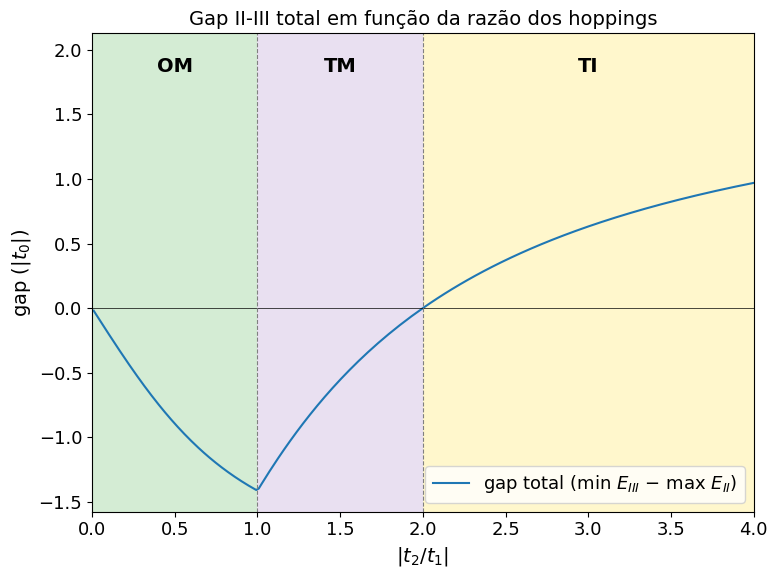

In [4]:
gap_glob = []
phis = np.linspace(0.01, np.pi/2 - 0.01, 200)

for phi in phis:
    ev = create_model(phi).solve_ham(k_pts=kmesh)           # (Nk, 4), ordenado
    gap_glob.append(np.min(ev[:, 2]) - np.max(ev[:, 1]))     # gap global

x = 1/np.tan(phis)    # |t2/t1|
xmax = 4

fig, ax = plt.subplots(figsize=(8, 6))

# --- regiões de fase ---
fases = [(0, 1, 'OM', 'tab:green'),
         (1, 2, 'TM', 'tab:purple'),
         (2, xmax, 'TI', 'gold')]
for x0, x1, nome, cor in fases:
    ax.axvspan(x0, x1, color=cor, alpha=0.2, lw=0)
    # texto no centro da região, na altura de 95% do eixo y
    ax.text((x0 + x1)/2, 0.95, nome, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, fontweight='bold')

# --- curvas dos gaps ---
ax.plot(x, gap_glob,   label='gap total (min $E_{III}$ − max $E_{II}$)')

ax.axhline(0, color='k', lw=0.5)
ax.axvline(1, ls='--', color='gray', lw=0.8)    # fronteira OM|TM
ax.axvline(2, ls='--', color='gray', lw=0.8)    # fronteira TM|TI

ax.set_title(r'Gap II-III total em função da razão dos hoppings')
ax.set_xlim(0, xmax)
ax.set_xlabel(r'$|t_2/t_1|$')
ax.set_ylabel(r'gap ($|t_0|$)')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig("GapTotal-TGrafeno.pdf")
plt.show()

## $\bullet$ Analisando a densidade de estados

Para analisar como os estados de energia se distribuem no T-grafeno a depender do  grau de quadrimerização.

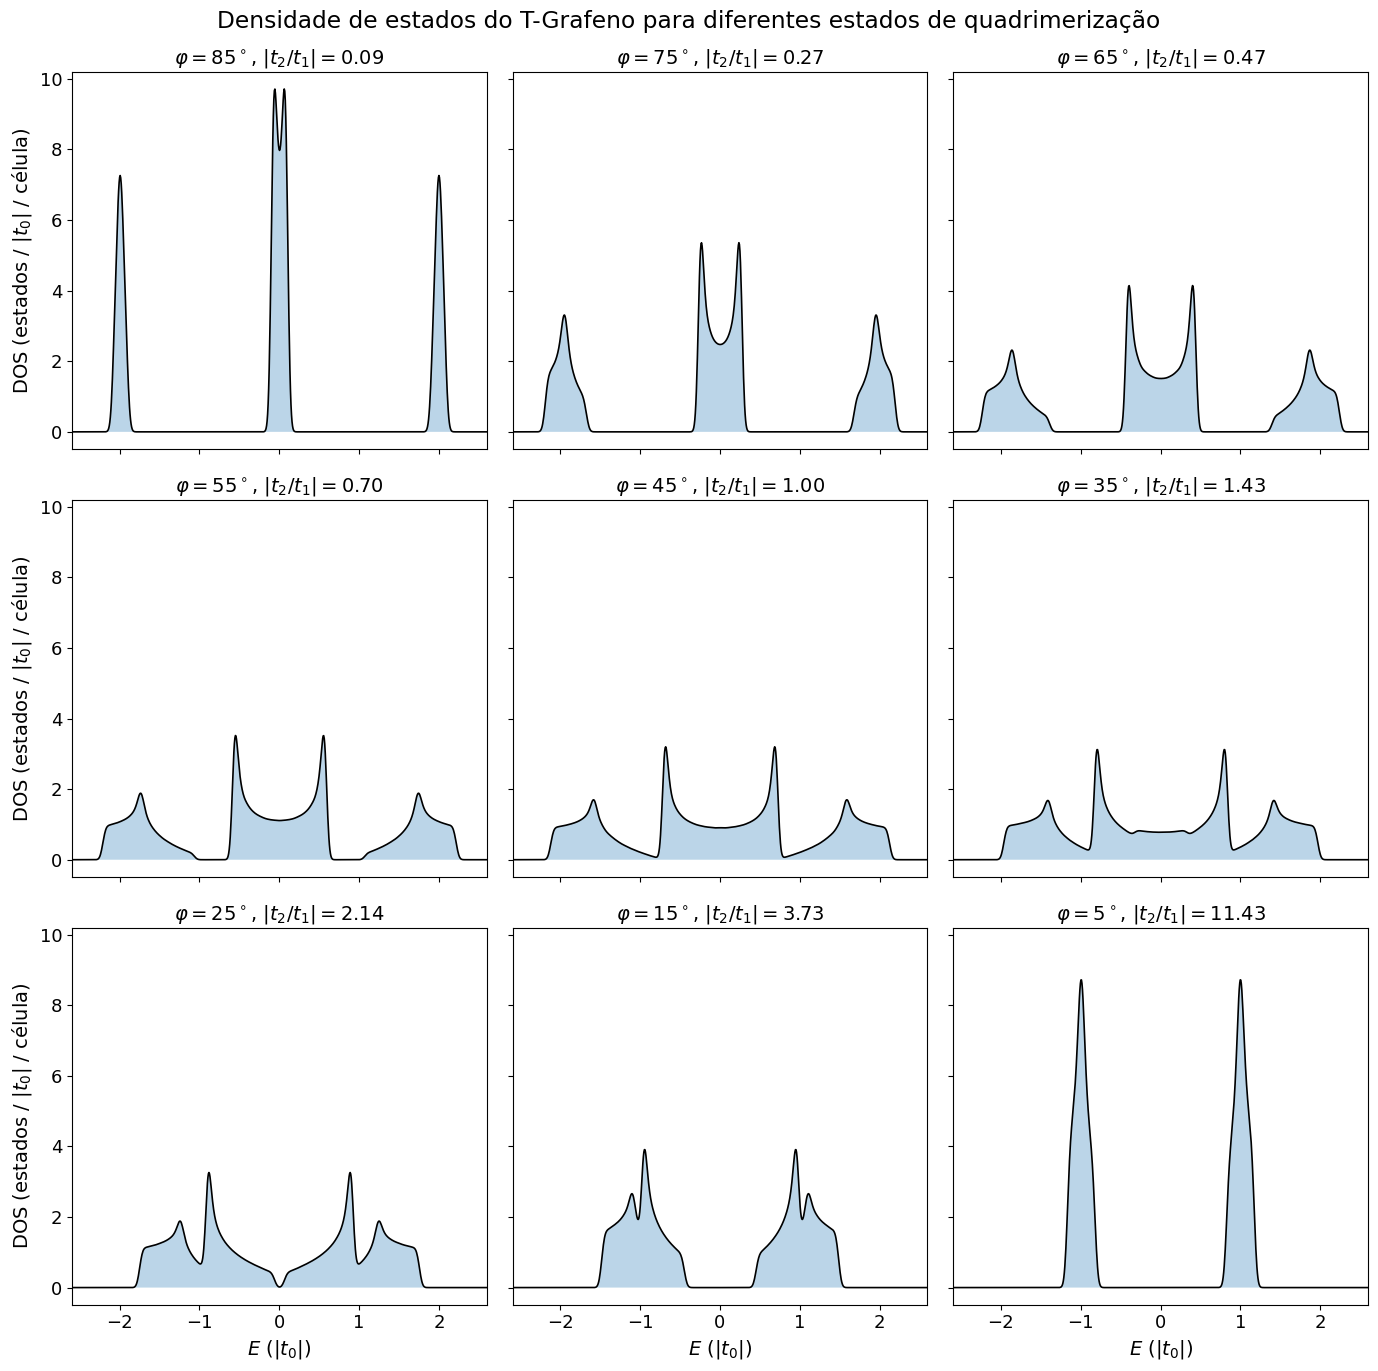

In [5]:
# --- Calculando a densidade de estados ---

def compute_dos(model, N=300, sigma=0.03, emin=-2.6, emax=2.6, nE=800):
    kmesh = [[i/N, j/N] for i in range(N) for j in range(N)] # malha uniforme N x N; i/N (sem o ponto N/N) evita contar k's equivalentes duas vezes
    ev = model.solve_ham(k_pts=kmesh).ravel() # todas as bandas juntas

    edges = np.linspace(emin, emax, nE + 1) # histograma das energias e suavização gaussiana
    E = 0.5*(edges[1:] + edges[:-1])
    dE = E[1] - E[0]
    hist, _ = np.histogram(ev, bins=edges)
    dos = hist/(N*N*dE) # estados / (energia · célula)

    xk = np.arange(-4*sigma, 4*sigma + dE, dE)
    kernel = np.exp(-0.5*(xk/sigma)**2)
    kernel /= kernel.sum()
    dos = np.convolve(dos, kernel, mode='same')

    return E, dos

fig, axs = plt.subplots(3, 3, figsize=(14, 14), sharex=True, sharey=True)

for ax, pdeg in zip(axs.flat, phis_deg):
    model = create_model(np.radians(pdeg))
    E, dos = compute_dos(model)
    ax.plot(E, dos, color='k', lw=1.2)
    ax.fill_between(E, dos, alpha=0.3)
    ax.set_xlim(E[0], E[-1])
    ax.set_title(rf"$\varphi={pdeg}^\circ$, $|t_2/t_1|={1/np.tan(np.radians(pdeg)):.2f}$")

for ax in axs[-1, :]:
    ax.set_xlabel(r"$E$ ($|t_0|$)")
for ax in axs[:, 0]:
    ax.set_ylabel("DOS (estados / $|t_0|$ / célula)")

fig.suptitle("Densidade de estados do T-Grafeno para diferentes estados de quadrimerização")
fig.tight_layout()
fig.savefig("DOS-TGrafeno.pdf")
plt.show()

## $\bullet$ Referência

Liang Yan et al. “Intrinsic topological metal state in T-graphene”. Em: New Journal
of Physics 25.4 (abr. de 2023), p. 043020. DOI: 10 . 1088 / 1367 - 2630 / acccd7.
(Acesso em 27/10/2026).